# Chest X-Ray Pneumonia Classification V5
### Biomedical image analysis code sample

This notebook presents a binary chest-radiograph classification workflow using TensorFlow/Keras and an ImageNet-initialized EfficientNetV2B0. It covers data auditing, grouped validation, reproducible preprocessing, two-stage training, validation-based threshold selection, quantitative evaluation and Grad-CAM.

**Review scope.** The default run verifies the archived V5 model and generates fresh predictions; it does not repeat training. The original 55-cell `Chest_XRay_Pneumonia_V5_Development_Record.ipynb` is preserved unchanged in `archive/`. Historical training observations are explicitly distinguished from computations performed during this run.

**Evidence boundary.** The official test folder was repeatedly inspected during V1–V4 development and informed V5's design. Its V5 results are a **historical benchmark evaluation**, not a fully untouched independent assessment or validated clinical performance. No medical-diagnosis, novelty or patient-independence claim is made.


## 1. Environment and reproducibility

Open the notebook from the extracted project directory and install `requirements.txt` into a separate Python environment. The accompanying README gives commands. All required model, policy, prediction and provenance files are in `assets/`; images are downloaded from the public dataset provider or read from an explicitly configured local dataset directory.

The configuration below is the only place to change run settings. `train_from_imagenet=False` is intentional: the selected V5 inference model is available. Missing assets stop the workflow rather than silently starting a new experiment. A fresh training run can be requested explicitly, but is not expected to reproduce the original weights bit for bit. Set seeds reduce stochastic variation; software, hardware and nondeterministic operations can still affect training.


For Colab, upload/extract the complete project bundle, install the pinned requirements and restart the runtime after changing dependencies. Set `CONFIG["project_root"]` to the extracted project directory; the source itself uses relative project paths. A configured external dataset directory is used in memory but its personal absolute path is omitted from shared outputs and exported configuration. The development-record digest is checked before any model inference.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import hashlib, importlib.metadata, json, os, platform, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow.keras import layers
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay,
)

CONFIG = {
    "project_root": ".",
    "source_archive_sha256": "d3e37ab99931ea8aae0b0709d0fef20b10884fb1fede769e664733ae6335bcb6",
    "dataset_root": os.environ.get("PNEUMONIA_DATA_ROOT"),
    "dataset_handle": "paultimothymooney/chest-xray-pneumonia",
    "train_from_imagenet": False,
    "seed": 42,
    "split_seed": 314,
    "class_names": ["NORMAL", "PNEUMONIA"],
    "image_size": 320,
    "batch_size": 16,
    "dtype_policy": "float32",
    "head_epochs": 4,
    "fine_tune_epochs": 10,
    "head_lr": 1e-3,
    "fine_tune_lr": 1e-5,
    "fine_tune_last_layers": 160,
    "dropout": 0.40,
    "label_smoothing": 0.04,
    "augmentation": {
        "rotation": 0.025,
        "translation": 0.04,
        "zoom": 0.10,
        "brightness": 0.12,
        "contrast": 0.20,
    },
    "augmentation_seed": 314,
    "dropout_seed": 319,
    "shuffle_buffer": 2000,
    "early_stopping_patience": 4,
    "lr_patience": 2,
    "lr_factor": 0.3,
    "min_lr": 1e-7,
    "precision_floor": 0.95,
    "recall_floor": 0.95,
    "threshold_grid": [i / 100 for i in range(1, 100)],
    "accuracy_metric_threshold": 0.50,
    "prediction_atol": 1e-5,
    "prediction_rtol": 1e-4,
    "decode_workers": 4,
    "hash_workers": 8,
    "heatmap_display_cutoff": 0.25,
    "overlay_alpha": 0.30,
    "figure_dpi": 85,
}
PROJECT_ROOT = Path(CONFIG["project_root"]).resolve()
ASSETS = PROJECT_ROOT / "assets"
if not (ASSETS / "integrity_manifest.json").is_file():
    raise FileNotFoundError(
        "Open this notebook from the extracted project root containing assets/ and requirements.txt."
    )
for name, expected in json.loads(
    (ASSETS / "integrity_manifest.json").read_text()
).items():
    path = ASSETS / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing required asset: {path}")
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        raise ValueError(f"Asset checksum mismatch: {name}")
original_policy = json.loads((ASSETS / "original_locked_policy.json").read_text())
original_manifest = json.loads((ASSETS / "original_split_manifest.json").read_text())
CLASS_NAMES = CONFIG["class_names"]
assert original_policy["class_names"] == CLASS_NAMES
SOURCE_PATH = PROJECT_ROOT / "archive/Chest_XRay_Pneumonia_V5_Development_Record.ipynb"
source_hash_before = hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()
assert (
    source_hash_before == CONFIG["source_archive_sha256"]
), "The development record does not match the recorded source SHA-256."
tf.keras.utils.set_random_seed(CONFIG["seed"])
tf.keras.mixed_precision.set_global_policy(CONFIG["dtype_policy"])
plt.rcParams.update(
    {
        "figure.dpi": CONFIG["figure_dpi"],
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
RUN_DIR = (
    PROJECT_ROOT / "results" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
)
RUN_DIR.mkdir(parents=True, exist_ok=False)
config_record = dict(CONFIG)
if config_record["dataset_root"] is not None:
    config_record["dataset_root"] = (
        "<external dataset directory supplied at execution; local path omitted>"
    )
(RUN_DIR / "config.json").write_text(json.dumps(config_record, indent=2))
print(
    "TensorFlow:",
    tf.__version__,
    "| Keras:",
    tf.keras.__version__,
    "| Python:",
    platform.python_version(),
)
print("Devices:", tf.config.list_physical_devices())
print(
    "Mode:",
    (
        "EXPLICIT FRESH TRAINING"
        if CONFIG["train_from_imagenet"]
        else "SAVED V5 MODEL VERIFICATION; no training"
    ),
)
print(
    "Output directory (relative to project):",
    RUN_DIR.relative_to(PROJECT_ROOT).as_posix(),
)
print("Development record SHA-256:", source_hash_before)
print("Required asset checksums passed.")


TensorFlow: 2.21.0 | Keras: 3.13.2 | Python: 3.12.14


Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Mode: SAVED V5 MODEL VERIFICATION; no training
Output directory (relative to project): results/20261022T185949_703755Z
Development record SHA-256: d3e37ab99931ea8aae0b0709d0fef20b10884fb1fede769e664733ae6335bcb6
Required asset checksums passed.


## 2. Dataset and labels

The source is [Chest X-Ray Images (Pneumonia) on Kaggle](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia), accessed through the official KaggleHub client. Class order is fixed as **NORMAL = 0, PNEUMONIA = 1**. Labels are inherited from the supplied folders; no clinical relabeling is performed. The original source contains 5,216 training images, 16 supplied validation images and 624 test images. Counts are checked below rather than assumed.

The supplied 16-image validation folder was not used for fitting or threshold selection. V5 instead derives a grouped validation subset from the source training folder. The supplied test folder is retained as the historical benchmark. Images are not redistributed in this project; obtain them from the provider under its applicable terms. The original run did not record a Kaggle dataset version number, so the saved per-file hashes provide the check on image identity.

`CONFIG['dataset_root']` can point to a local directory containing `train/`, `val/` and `test/`. Otherwise KaggleHub downloads the public resource to its cache. No credentials are embedded. If the provider requests authentication or consent, complete that through its normal interface rather than adding secrets to the notebook.


**Attribution and sharing.** Dataset authors: Daniel Kermany, Kang Zhang and Michael Goldbaum, [Mendeley Data v2, DOI: 10.17632/rscbjbr9sj.2](https://data.mendeley.com/datasets/rscbjbr9sj/2), whose record lists [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The Kaggle mirror supplies the actual files used here. Raw images are excluded from this bundle. Displayed examples are resized and Grad-CAM overlays are added for analysis; labels are not changed. See `THIRD_PARTY_NOTICES.md` for the scope of the rights check.

In [2]:
def locate_dataset_root(download_root):
    download_root = Path(download_root)
    candidates = [
        p
        for p in [download_root, *download_root.rglob("chest_xray")]
        if all((p / s / c).is_dir() for s in ["train", "test"] for c in CLASS_NAMES)
    ]
    if not candidates:
        raise FileNotFoundError(
            "No train/NORMAL and test/PNEUMONIA dataset structure found."
        )
    return min(candidates, key=lambda p: (len(p.parts), str(p)))


if CONFIG["dataset_root"] is None:
    import kagglehub

    DATA_ROOT = locate_dataset_root(
        kagglehub.dataset_download(CONFIG["dataset_handle"])
    )
else:
    DATA_ROOT = locate_dataset_root(CONFIG["dataset_root"])
suffixes = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}


def image_files(folder):
    return sorted(
        p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in suffixes
    )


source_paths = image_files(DATA_ROOT / "train")
historical_paths = image_files(DATA_ROOT / "test")
supplied_validation_paths = image_files(DATA_ROOT / "val")


def relative(path):
    return Path(path).relative_to(DATA_ROOT).as_posix()


def class_id(path):
    return CLASS_NAMES.index(Path(path).parent.name)


def filename_proxy(path):
    """Return a filename-derived grouping proxy, not a verified patient ID."""
    name = Path(path).name
    match = re.match(r"person(\d+)_", name, re.I)
    if match:
        return "pneumonia_person_" + match.group(1)
    match = re.match(r"(NORMAL2-)?IM-(\d+)-", name, re.I)
    if match:
        return ("normal2_" if match.group(1) else "normal1_") + match.group(2)
    raise ValueError("Unrecognized filename proxy: " + name)


def filename_source(path):
    return (
        "PNEUMONIA"
        if class_id(path) == 1
        else ("NORMAL2" if Path(path).name.startswith("NORMAL2-") else "IM")
    )


raw_distribution = (
    pd.DataFrame(
        {
            name: dict(Counter(Path(p).parent.name for p in paths))
            for name, paths in [
                ("source_train", source_paths),
                ("supplied_val_unused", supplied_validation_paths),
                ("historical_test", historical_paths),
            ]
        }
    )
    .fillna(0)
    .astype(int)
)
display(raw_distribution)
print(
    "Dataset location: external directory supplied in CONFIG or the provider cache; personal path omitted."
)


,source_train,supplied_val_unused,historical_test
NORMAL,1341,8,234
PNEUMONIA,3875,8,390


Dataset location: external directory supplied in CONFIG or the provider cache; personal path omitted.


In [3]:
def file_digest(path):
    return relative(path), hashlib.sha256(Path(path).read_bytes()).hexdigest()


all_paths = source_paths + supplied_validation_paths + historical_paths
with ThreadPoolExecutor(max_workers=CONFIG["hash_workers"]) as workers:
    image_hashes = dict(workers.map(file_digest, all_paths))
inventory = pd.DataFrame(
    [
        dict(
            file=relative(p),
            label=class_id(p),
            sha256=image_hashes[relative(p)],
            supplied_folder=p.parent.parent.name,
            filename_proxy=filename_proxy(p),
            filename_source=filename_source(p),
        )
        for p in all_paths
    ]
)
conflicting = inventory.groupby("sha256")["label"].nunique().loc[lambda s: s > 1]
conflicting.to_csv(RUN_DIR / "conflicting_hash_labels.csv")
assert (
    conflicting.empty
), "Identical bytes have conflicting labels; investigate before reporting."
for file, expected in {
    **original_manifest["hashes"],
    **original_manifest["historical_test_hashes"],
}.items():
    assert (
        image_hashes.get(file) == expected
    ), f"Image bytes differ from the archived V5 manifest: {file}"
inventory.to_csv(RUN_DIR / "image_inventory.csv", index=False)
raw_hash_audit = (
    inventory.groupby("supplied_folder")
    .agg(files=("file", "size"), unique_hashes=("sha256", "nunique"))
    .reset_index()
)
display(raw_hash_audit)
print("Actual source-pool and historical image bytes match all saved manifest hashes.")
print("Conflicting labels on identical bytes:", len(conflicting))


,supplied_folder,files,unique_hashes
0,test,624,618
1,train,5216,5190
2,val,16,16


Actual source-pool and historical image bytes match all saved manifest hashes.
Conflicting labels on identical bytes: 0


## 3. Dataset splitting and leakage checks

V5 forms connected components from filename proxies and SHA-256 matches. It excludes source-training components sharing a proxy or exact bytes with the historical test, removes remaining exact duplicates in deterministic file order, then takes the first fold of `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=314)`. The strata are NORMAL/IM, NORMAL/NORMAL2 and PNEUMONIA. This reconstructs the actual saved split and checks it against the manifest.

These checks reduce specific forms of overlap. **Filename prefixes and person-like identifiers are proxies, not verified patient or site IDs.** Byte hashes detect identical files, not re-encoded images or near-duplicates. The historical test's filenames and byte identity also informed the quarantine procedure; that does not restore its status as untouched external evidence.

The earlier image-level split had **7 shared exact-byte hashes and 409 shared filename-proxy groups** across training and validation (saved audit in source cells 24 and 39). That evidence remains in the original record. V5's different split does not retrospectively correct earlier experiments.


In [4]:
parent = {filename_proxy(p): filename_proxy(p) for p in source_paths}


def component(key):
    while parent[key] != key:
        parent[key] = parent[parent[key]]
        key = parent[key]
    return key


first_for_hash = {}
for path in source_paths:
    digest = image_hashes[relative(path)]
    if digest in first_for_hash:
        a, b = component(filename_proxy(path)), component(
            filename_proxy(first_for_hash[digest])
        )
        parent[max(a, b)] = min(a, b)
    else:
        first_for_hash[digest] = path
historical_proxy_set = {filename_proxy(p) for p in historical_paths}
historical_hash_set = {image_hashes[relative(p)] for p in historical_paths}
quarantined = {
    component(filename_proxy(p))
    for p in source_paths
    if filename_proxy(p) in historical_proxy_set
    or image_hashes[relative(p)] in historical_hash_set
}
pool, removed, seen = [], [], set()
for path in source_paths:
    digest = image_hashes[relative(path)]
    if component(filename_proxy(path)) in quarantined:
        removed.append(
            dict(file=relative(path), reason="historical_proxy_or_byte_component")
        )
    elif digest in seen:
        removed.append(dict(file=relative(path), reason="remaining_exact_duplicate"))
    else:
        pool.append(path)
        seen.add(digest)
strata = np.array(
    [2 if class_id(p) == 1 else int(p.name.startswith("NORMAL2-")) for p in pool]
)
group_keys = np.array([component(filename_proxy(p)) for p in pool])
fit_idx, val_idx = next(
    StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=CONFIG["split_seed"]
    ).split(pool, strata, group_keys)
)
fit_paths = [pool[i] for i in fit_idx]
validation_paths = [pool[i] for i in val_idx]
splits = {
    "train": fit_paths,
    "validation": validation_paths,
    "historical_test": historical_paths,
}
reconstructed = {name: [relative(p) for p in paths] for name, paths in splits.items()}
assert (
    reconstructed == original_manifest["files"]
), "Reconstructed split differs from the model's saved split."
overlaps = []
for a, b in [
    ("train", "validation"),
    ("train", "historical_test"),
    ("validation", "historical_test"),
]:
    row = dict(
        pair=f"{a} / {b}",
        paths=len(set(reconstructed[a]) & set(reconstructed[b])),
        exact_hashes=len(
            {image_hashes[relative(p)] for p in splits[a]}
            & {image_hashes[relative(p)] for p in splits[b]}
        ),
        filename_proxies=len(
            {filename_proxy(p) for p in splits[a]}
            & {filename_proxy(p) for p in splits[b]}
        ),
    )
    assert row["paths"] == row["exact_hashes"] == row["filename_proxies"] == 0
    overlaps.append(row)
assert not (set(group_keys[fit_idx]) & set(group_keys[val_idx]))
split_distribution = (
    pd.DataFrame(
        {
            s: dict(Counter(Path(p).parent.name for p in paths))
            for s, paths in splits.items()
        }
    )
    .fillna(0)
    .astype(int)
)
source_distribution = (
    pd.DataFrame(
        {
            s: dict(Counter(filename_source(p) for p in paths))
            for s, paths in splits.items()
        }
    )
    .fillna(0)
    .astype(int)
)
display(split_distribution)
display(source_distribution)
display(pd.DataFrame(overlaps))
print("Removed source images:", dict(Counter(r["reason"] for r in removed)))
(RUN_DIR / "split_verification.json").write_text(
    json.dumps(dict(files=reconstructed, overlaps=overlaps, removed=removed), indent=2)
)


,train,validation,historical_test
NORMAL,1071,269,234
PNEUMONIA,2710,687,390


,train,validation,historical_test
IM,477,120,69
NORMAL2,594,149,165
PNEUMONIA,2710,687,390


,pair,paths,exact_hashes,filename_proxies
0,train / validation,0,0,0
1,train / historical_test,0,0,0
2,validation / historical_test,0,0,0


Removed source images: {'remaining_exact_duplicate': 22, 'historical_proxy_or_byte_component': 457}


331827

## 4. Preprocessing, augmentation and class balance

Every path uses TensorFlow decoding with three channels, float32 pixels in **0–255**, and bilinear resizing to **320 × 320**, with no external division by 255. Aspect ratio is not preserved by this original resize operation. No lung segmentation, DICOM normalization or fitted dataset-level intensity normalization is applied. EfficientNetV2's rescaling is embedded in the model.

Training-only augmentation uses rotation 0.025 turns, translation 0.04 on each axis, zoom 0.10, brightness 0.12 and contrast 0.20. The geometric layers use reflected filling. Seeds 314–318 are fixed for these layers, and dropout uses seed 319. The transformations are regularization choices; this project has no controlled ablation establishing their incremental benefit or clinical validity.

Class weights use `n_training / (2 × class_count)` from the fitting subset only. Validation and evaluation retain their actual prevalence. All prediction, reload and Grad-CAM calls use `training=False`, disabling augmentation and dropout at inference.


In [5]:
def decode_image(path):
    """Apply the original model's RGB, float32 and bilinear resize contract."""
    image = tf.io.decode_image(
        tf.io.read_file(path), channels=3, expand_animations=False
    )
    image = tf.image.resize(
        image,
        (CONFIG["image_size"], CONFIG["image_size"]),
        method="bilinear",
        antialias=False,
    )
    image.set_shape((CONFIG["image_size"], CONFIG["image_size"], 3))
    return tf.cast(image, tf.float32)


def ordered_dataset(paths):
    """Preserve file/label order for exported predictions and audit checks."""
    labels = np.array([class_id(p) for p in paths], dtype=np.float32)

    def decode(path, label):
        return decode_image(path), tf.reshape(label, (1,))

    ds = tf.data.Dataset.from_tensor_slices(([str(p) for p in paths], labels))
    return (
        ds.map(decode, num_parallel_calls=CONFIG["decode_workers"], deterministic=True)
        .batch(CONFIG["batch_size"])
        .prefetch(2)
    )


def predict_scores(network, paths):
    """Generate finite uncalibrated scores with augmentation/dropout disabled."""
    scores = np.concatenate(
        [
            np.asarray(network(images, training=False)).ravel()
            for images, _ in ordered_dataset(paths)
        ]
    )
    assert (
        len(scores) == len(paths)
        and np.isfinite(scores).all()
        and ((scores >= 0) & (scores <= 1)).all()
    )
    return scores


validation_y = np.array([class_id(p) for p in validation_paths])
class_counts = Counter(class_id(p) for p in fit_paths)
class_weights = {c: len(fit_paths) / (2 * count) for c, count in class_counts.items()}
print("Fitting class weights:", {CLASS_NAMES[c]: v for c, v in class_weights.items()})
sample = decode_image(str(validation_paths[0]))
print(
    "Decoded shape:",
    sample.shape,
    "| dtype:",
    sample.dtype,
    "| resized range:",
    float(tf.reduce_min(sample)),
    float(tf.reduce_max(sample)),
)


Fitting class weights: {'NORMAL': 1.765172735760971, 'PNEUMONIA': 0.6976014760147602}
Decoded shape: (320, 320, 3) | dtype: <dtype: 'float32'> | resized range: 0.0 255.0


## 5. Model architecture

The V5 network is: RGB image → augmentation → EfficientNetV2B0 features → a named linear feature layer → global average pooling → dropout 0.40 → one sigmoid output. ImageNet initialization and a compact transfer-learning backbone were practical design choices. A 320-pixel input was chosen to retain spatial detail within the available compute budget; no matched resolution ablation proves that 320 is superior to 224.

The original builder is rewritten below with descriptive names. The saved model is loaded with `compile=False`; its complete weights are sufficient for inference. The embedded preprocessing, inference-time backbone call, layer flags and augmentation configuration are checked against the actual artifact. Training provenance comes from source code and logs, rather than being inferred from weights alone.

Input contract: [Keras EfficientNetV2 documentation](https://keras.io/api/applications/efficientnet_v2/efficientnet_v2_models/).


In [6]:
def build_v5(weights="imagenet"):
    """Build the original V5 feature extractor and binary classification head."""
    inputs = layers.Input(
        (CONFIG["image_size"], CONFIG["image_size"], 3), dtype="float32", name="image"
    )
    aug = CONFIG["augmentation"]
    seed = CONFIG["augmentation_seed"]
    augmentation = tf.keras.Sequential(
        [
            layers.RandomRotation(aug["rotation"], fill_mode="reflect", seed=seed),
            layers.RandomTranslation(
                aug["translation"],
                aug["translation"],
                fill_mode="reflect",
                seed=seed + 1,
            ),
            layers.RandomZoom(aug["zoom"], fill_mode="reflect", seed=seed + 2),
            layers.RandomBrightness(
                aug["brightness"], value_range=(0, 255), seed=seed + 3
            ),
            layers.RandomContrast(aug["contrast"], seed=seed + 4),
        ],
        name="augmentation",
    )
    backbone = tf.keras.applications.EfficientNetV2B0(
        include_top=False,
        weights=weights,
        input_shape=(CONFIG["image_size"], CONFIG["image_size"], 3),
        include_preprocessing=True,
    )
    backbone.trainable = False
    x = backbone(augmentation(inputs), training=False)
    x = layers.Activation("linear", name="last_conv_features")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(CONFIG["dropout"], seed=CONFIG["dropout_seed"])(x)
    score = layers.Dense(1, activation="sigmoid", dtype="float32", name="prediction")(x)
    return tf.keras.Model(inputs, score, name="v5_EfficientNetV2B0_320"), backbone


MODEL_PATH = ASSETS / "selected_model.keras"
saved_model_hash = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
assert saved_model_hash == original_policy["model_sha256"]
if CONFIG["train_from_imagenet"]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(CONFIG["seed"])
    tf.keras.mixed_precision.set_global_policy(CONFIG["dtype_policy"])
    model, backbone = build_v5()
else:
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    backbone = next(
        layer
        for layer in model.layers
        if isinstance(layer, tf.keras.Model) and layer.name.startswith("efficientnetv2")
    )
assert model.input_shape == (None, 320, 320, 3) and model.output_shape == (None, 1)
assert model.compute_dtype == "float32"
assert not any(
    isinstance(layer, layers.BatchNormalization) and layer.trainable
    for layer in backbone.layers
)
assert any(isinstance(layer, layers.Rescaling) for layer in backbone.layers)
graph = next(
    layer
    for layer in model.get_config()["layers"]
    if layer["config"]["name"] == backbone.name
)
assert all(
    node.get("kwargs", {}).get("training") is False for node in graph["inbound_nodes"]
)
augmentation = model.get_layer("augmentation")
display(
    pd.DataFrame(
        [
            dict(
                layer=l.name,
                operation=type(l).__name__,
                seed=l.get_config().get("seed"),
                compute_dtype=l.compute_dtype,
            )
            for l in augmentation.layers
        ]
    )
)
print(
    "Backbone layers:",
    len(backbone.layers),
    "| trainable layer flags:",
    sum(l.trainable for l in backbone.layers),
)
print("Trainable BatchNormalization layers: 0 | built-in rescaling: present")
model.summary()


,layer,operation,seed,compute_dtype
0,random_rotation,RandomRotation,314,float32
1,random_translation,RandomTranslation,315,float32
2,random_zoom,RandomZoom,316,float32
3,random_brightness,RandomBrightness,317,float32
4,random_contrast,RandomContrast,318,float32


Backbone layers: 270 | trainable layer flags: 129
Trainable BatchNormalization layers: 0 | built-in rescaling: present


Model: "v5_EfficientNetV2B0_320"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 10, 10, 1280)   │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv_features (Activation) │ (None, 10, 10, 1280)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,920,593 (22.59 MB)

 Trainable params: 4,950,817 (18.89 MB)

 Non-trainable params: 969,776 (3.70 MB)

## 6. Training and fine-tuning

The original V5 trained the head for four epochs at Adam learning rate 0.001, then fine-tuned for at most ten epochs at 0.00001. Only non-batch-normalization layers within the last 160 backbone layers were enabled. This means **128 enabled layer flags in the saved 270-layer backbone**, not 160 trainable convolutional layers. Binary cross-entropy used label smoothing 0.04. Early stopping monitored validation loss with patience four; learning-rate reduction used factor 0.3, patience two and minimum 1e-7.

At each epoch, validation predictions determine a feasible operating point with precision and recall ≥ 0.95. Within an epoch, specificity, F1 and higher threshold rank feasible points. Across epochs, the checkpoint key is `(feasible, specificity, F1, ROC-AUC)`; infeasible checkpoints use F1 for the second key. The same checkpoint tracker spans both phases. Best head weights are loaded before fine-tuning, and the best tracked weights are loaded before export. The saved record identifies fine-tuning epoch ten as the final selected checkpoint.

The code below implements this procedure. In the default verification run the `fit()` branch is skipped. An explicit fresh run saves native `History.history` dictionaries for both phases and per-epoch selection records. **Training accuracy uses threshold 0.50**; final classification uses the separate validation-selected threshold. Class-weighted, augmented training loss and unweighted, unaugmented validation loss are not directly comparable measures of data difficulty.

Layer-freezing behavior: [Keras transfer learning guide](https://keras.io/guides/transfer_learning/).


In [7]:
def binary_metrics(truth, scores, threshold):
    """Compute image-level metrics with PNEUMONIA as the positive class."""
    tn, fp, fn, tp = confusion_matrix(
        truth, (np.asarray(scores) >= threshold).astype(int), labels=[0, 1]
    ).ravel()
    return dict(
        threshold=float(threshold),
        n=len(truth),
        tn=int(tn),
        fp=int(fp),
        fn=int(fn),
        tp=int(tp),
        accuracy=float((tn + tp) / len(truth)),
        precision=float(tp / (tp + fp)) if tp + fp else 0.0,
        recall=float(tp / (tp + fn)),
        specificity=float(tn / (tn + fp)),
        f1=float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else 0.0,
        roc_auc=float(roc_auc_score(truth, scores)),
    )


def validation_policy(scores, deployment=False):
    """Select on validation only, preserving the two historical tie-break rules."""
    grid = pd.DataFrame(
        [binary_metrics(validation_y, scores, t) for t in CONFIG["threshold_grid"]]
    )
    feasible = grid.loc[
        (grid["precision"] >= CONFIG["precision_floor"])
        & (grid["recall"] >= CONFIG["recall_floor"])
    ]
    columns = (
        ["specificity", "threshold", "f1"]
        if deployment
        else ["specificity", "f1", "threshold"]
    )
    chosen = (
        feasible.sort_values(columns, ascending=False, kind="stable").iloc[0]
        if len(feasible)
        else grid.sort_values(
            ["f1", "specificity", "threshold"], ascending=False, kind="stable"
        ).iloc[0]
    )
    result = binary_metrics(validation_y, scores, float(chosen["threshold"]))
    result["constraints_met"] = bool(len(feasible))
    return result, grid


def compile_for_training(network, learning_rate):
    network.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.BinaryCrossentropy(
            label_smoothing=CONFIG["label_smoothing"]
        ),
        metrics=[
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.BinaryAccuracy(
                name="accuracy", threshold=CONFIG["accuracy_metric_threshold"]
            ),
        ],
    )


class ValidationCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.phase = "head"
        self.best_key = None
        self.selection_rows = []
        self.metric_rows = []
        self.path = RUN_DIR / "best.weights.h5"

    def on_epoch_end(self, epoch, logs=None):
        result, _ = validation_policy(predict_scores(self.model, validation_paths))
        feasible = result["constraints_met"]
        key = (
            int(feasible),
            result["specificity"] if feasible else result["f1"],
            result["f1"],
            result["roc_auc"],
        )
        self.selection_rows.append(dict(result, phase=self.phase, epoch=epoch + 1))
        self.metric_rows.append(
            dict(
                phase=self.phase,
                epoch=epoch + 1,
                **{k: float(v) for k, v in (logs or {}).items()},
            )
        )
        if self.best_key is None or key > self.best_key:
            self.best_key = key
            self.model.save_weights(self.path)
        pd.DataFrame(self.selection_rows).to_csv(
            RUN_DIR / "checkpoint_selection.csv", index=False
        )
        pd.DataFrame(self.metric_rows).to_csv(
            RUN_DIR / "epoch_metric_logs.csv", index=False
        )


native_history_rows = []
if CONFIG["train_from_imagenet"]:
    fitting = (
        ordered_dataset(fit_paths)
        .unbatch()
        .cache()
        .shuffle(
            min(CONFIG["shuffle_buffer"], len(fit_paths)),
            seed=CONFIG["seed"],
            reshuffle_each_iteration=True,
        )
        .batch(CONFIG["batch_size"])
        .prefetch(2)
    )
    checkpoint = ValidationCheckpoint()

    def callbacks():
        return [
            checkpoint,
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=CONFIG["early_stopping_patience"],
                restore_best_weights=False,
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=CONFIG["lr_factor"],
                patience=CONFIG["lr_patience"],
                min_lr=CONFIG["min_lr"],
            ),
        ]

    for phase, epochs, learning_rate in [
        ("head", CONFIG["head_epochs"], CONFIG["head_lr"]),
        ("fine_tune", CONFIG["fine_tune_epochs"], CONFIG["fine_tune_lr"]),
    ]:
        if phase == "fine_tune":
            model.load_weights(checkpoint.path)
            backbone.trainable = True
            for layer in backbone.layers:
                layer.trainable = False
            for layer in backbone.layers[-CONFIG["fine_tune_last_layers"] :]:
                if not isinstance(layer, layers.BatchNormalization):
                    layer.trainable = True
        checkpoint.phase = phase
        compile_for_training(model, learning_rate)
        history = model.fit(
            fitting,
            validation_data=ordered_dataset(validation_paths),
            epochs=epochs,
            class_weight=class_weights,
            callbacks=callbacks(),
            verbose=2,
        )
        values = {k: [float(v) for v in seq] for k, seq in history.history.items()}
        (RUN_DIR / f"{phase}_history.json").write_text(json.dumps(values, indent=2))
        native_history_rows.extend(
            dict(phase=phase, epoch=i + 1, **{k: seq[i] for k, seq in values.items()})
            for i in range(len(values["loss"]))
        )
    model.load_weights(checkpoint.path)
    MODEL_PATH = RUN_DIR / "fresh_selected_model.keras"
    tf.keras.Model(model.inputs, model.outputs, name=model.name).save(MODEL_PATH)
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
else:
    print(
        "Original saved V5 weights loaded; training and optimizer resume were not performed."
    )
model_hash = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()


Original saved V5 weights loaded; training and optimizer resume were not performed.


### Training curves and their provenance

The original V5 `fit()` calls did not retain `History` objects. The following curves use the **four-decimal console metrics from source cell 49**, with four head epochs and ten fine-tuning epochs. These are saved historical observations, not new training logs from this verification run. The original stdout and its notebook/model checksum provenance are included in `assets/`. A model-hash check prevents attaching these curves to other weights. If explicit fresh training is enabled, its native histories are plotted instead.

The dashed boundary marks fine-tuning. Keras' epoch AUC is an approximation from the training metric; final ROC-AUC below is recomputed from individual prediction scores. Accuracy here uses **0.50**, so it should not be compared directly with accuracy reported at the final threshold.


Original V5 console records, rounded to four decimals; not native History


,phase,epoch,accuracy,auc,loss,val_accuracy,val_auc,val_loss,learning_rate,global_epoch
0,head,1,0.8223,0.9173,0.4168,0.9320,0.9811,0.2538,0.001000,1
1,head,2,0.9051,0.9717,0.2840,0.9456,0.9850,0.2276,0.001000,2
2,head,3,0.9222,0.9780,0.2586,0.9425,0.9872,0.2206,0.001000,3
3,head,4,0.9286,0.9816,0.2455,0.9561,0.9890,0.2066,0.001000,4
4,fine_tune,1,0.9371,0.9865,0.2243,0.9561,0.9924,0.1992,0.000010,5
5,fine_tune,2,0.9482,0.9904,0.2061,0.9644,0.9939,0.1810,0.000010,6
6,fine_tune,3,0.9550,0.9934,0.1924,0.9634,0.9952,0.1872,0.000010,7
7,fine_tune,4,0.9603,0.9935,0.1875,0.9623,0.9959,0.1868,0.000010,8
8,fine_tune,5,0.9624,0.9950,0.1787,0.9676,0.9963,0.1699,0.000003,9
9,fine_tune,6,0.9701,0.9961,0.1726,0.9707,0.9965,0.1676,0.000003,10


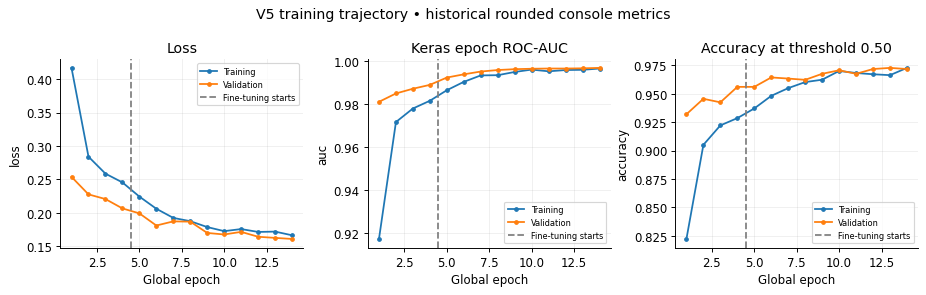

In [8]:
if native_history_rows:
    history_frame = pd.DataFrame(native_history_rows)
    history_source = "Native Keras History from this explicit fresh-training run"
else:
    history_provenance = json.loads(
        (ASSETS / "training_history_provenance.json").read_text()
    )
    assert model_hash == history_provenance["model_sha256"]
    history_frame = pd.read_csv(ASSETS / "recovered_training_history.csv")
    history_source = (
        "Original V5 console records, rounded to four decimals; not native History"
    )
history_frame["global_epoch"] = np.arange(1, len(history_frame) + 1)
history_frame.to_csv(RUN_DIR / "training_metric_history.csv", index=False)
print(history_source)
display(history_frame)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
boundary = int((history_frame["phase"] == "head").sum()) + 0.5
for ax, metric, title in zip(
    axes,
    ["loss", "auc", "accuracy"],
    ["Loss", "Keras epoch ROC-AUC", "Accuracy at threshold 0.50"],
):
    ax.plot(
        history_frame["global_epoch"],
        history_frame[metric],
        "-o",
        markersize=3,
        label="Training",
    )
    ax.plot(
        history_frame["global_epoch"],
        history_frame["val_" + metric],
        "-o",
        markersize=3,
        label="Validation",
    )
    ax.axvline(boundary, color="gray", linestyle="--", label="Fine-tuning starts")
    ax.set(xlabel="Global epoch", ylabel=metric, title=title)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7)
fig.suptitle(
    "V5 training trajectory • "
    + (
        "native History"
        if native_history_rows
        else "historical rounded console metrics"
    )
)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Validation-based threshold selection

The precision/recall floors of 0.95 are **project-defined validation selection targets**, not accepted clinical standards or guarantees for new data. On the 0.01–0.99 grid, final threshold selection retains points satisfying both floors, maximizes specificity, then favors the higher threshold and F1 in that order. If no point is feasible, evaluation stops.

This final threshold tie-break differs from the within-epoch checkpoint operating-point tie-break. The distinction is preserved because it is part of the recorded experiment. Source cell 50 calls it a validation-stage calibration addendum and explicitly does not claim full preregistration. The value **0.72 is recomputed**, not assigned as a target to obtain a preferred test result.


,threshold,n,tn,fp,fn,tp,accuracy,precision,recall,specificity,f1,roc_auc,feasible
14,0.15,956,233,36,2,685,0.960251,0.950069,0.997089,0.866171,0.973011,0.996954,True
15,0.16,956,233,36,2,685,0.960251,0.950069,0.997089,0.866171,0.973011,0.996954,True
16,0.17,956,236,33,3,684,0.962343,0.953975,0.995633,0.877323,0.974359,0.996954,True
17,0.18,956,237,32,3,684,0.963389,0.955307,0.995633,0.881041,0.975053,0.996954,True
18,0.19,956,240,29,3,684,0.966527,0.959327,0.995633,0.892193,0.977143,0.996954,True
19,0.20,956,241,28,3,684,0.967573,0.960674,0.995633,0.895911,0.977841,0.996954,True
20,0.21,956,242,27,4,683,0.967573,0.961972,0.994178,0.899628,0.977810,0.996954,True
21,0.22,956,243,26,4,683,0.968619,0.963329,0.994178,0.903346,0.978510,0.996954,True
22,0.23,956,244,25,4,683,0.969665,0.964689,0.994178,0.907063,0.979211,0.996954,True
23,0.24,956,245,24,4,683,0.970711,0.966054,0.994178,0.910781,0.979914,0.996954,True


Locked threshold: 0.72 | validation prediction max difference from archive: 1.405004348753458e-06
Reload probe maximum difference: 0.0


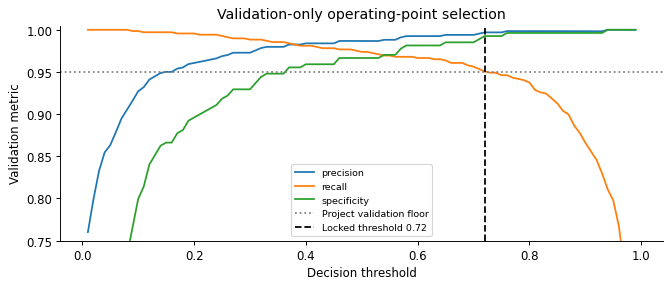

In [9]:
validation_scores = predict_scores(model, validation_paths)
validation_result, threshold_grid = validation_policy(
    validation_scores, deployment=True
)
if not validation_result["constraints_met"]:
    raise RuntimeError(
        "No validation threshold meets both project floors; historical evaluation stopped."
    )
THRESHOLD = validation_result["threshold"]
original_validation = pd.read_csv(ASSETS / "original_validation_predictions.csv")
assert original_validation["file"].tolist() == reconstructed["validation"]
np.testing.assert_array_equal(original_validation["y_true"], validation_y)
validation_max_error = None
if not CONFIG["train_from_imagenet"]:
    validation_max_error = float(
        np.max(np.abs(validation_scores - original_validation["p_pneumonia"]))
    )
    np.testing.assert_allclose(
        validation_scores,
        original_validation["p_pneumonia"],
        atol=CONFIG["prediction_atol"],
        rtol=CONFIG["prediction_rtol"],
    )
    assert (
        THRESHOLD == original_policy["decision_threshold"]
    ), "Recomputed threshold disagrees with the original policy."
reloaded = tf.keras.models.load_model(MODEL_PATH, compile=False)
probe_paths = validation_paths[: CONFIG["batch_size"]]
probe_a = predict_scores(model, probe_paths)
probe_b = predict_scores(reloaded, probe_paths)
np.testing.assert_allclose(
    probe_a, probe_b, atol=CONFIG["prediction_atol"], rtol=CONFIG["prediction_rtol"]
)
reload_max_error = float(np.max(np.abs(probe_a - probe_b)))
pd.DataFrame(
    dict(
        file=reconstructed["validation"],
        y_true=validation_y,
        p_pneumonia=validation_scores,
    )
).to_csv(RUN_DIR / "validation_predictions.csv", index=False)
threshold_grid["feasible"] = (
    threshold_grid["precision"] >= CONFIG["precision_floor"]
) & (threshold_grid["recall"] >= CONFIG["recall_floor"])
threshold_grid.to_csv(RUN_DIR / "validation_threshold_grid.csv", index=False)
run_policy = dict(
    model_sha256=model_hash,
    threshold=THRESHOLD,
    comparison="score >= threshold",
    selection_dataset="grouped_source_stratified_validation",
    validation_metrics=validation_result,
    rule="precision/recall floors; maximize specificity, higher threshold, F1",
    independent_test=False,
)
(RUN_DIR / "locked_run_policy.json").write_text(json.dumps(run_policy, indent=2))
display(
    threshold_grid.loc[
        threshold_grid["feasible"]
        | ((threshold_grid["threshold"] - THRESHOLD).abs() <= 0.03)
    ]
)
print(
    "Locked threshold:",
    THRESHOLD,
    "| validation prediction max difference from archive:",
    validation_max_error,
)
print("Reload probe maximum difference:", reload_max_error)
fig, ax = plt.subplots(figsize=(8, 3.5))
for metric in ["precision", "recall", "specificity"]:
    ax.plot(threshold_grid["threshold"], threshold_grid[metric], label=metric)
ax.axhline(
    CONFIG["precision_floor"],
    color="gray",
    linestyle=":",
    label="Project validation floor",
)
ax.axvline(
    THRESHOLD, color="black", linestyle="--", label=f"Locked threshold {THRESHOLD:.2f}"
)
ax.set(
    xlabel="Decision threshold",
    ylabel="Validation metric",
    ylim=(0.75, 1.005),
    title="Validation-only operating-point selection",
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "validation_threshold_selection.png", dpi=160)
plt.show()
del reloaded


## 8. Historical benchmark evaluation

The source documents test-threshold selection in V1, a validation-based correction in V2, grouped candidate/ensemble development in V3 and normalization/source-proxy experiments in V4. The historical NORMAL error analysis in source cell 37 further demonstrates that test results became development feedback. V5 was designed after those outcomes. Selecting its own threshold on validation does not remove this adaptive history.

This section generates **fresh scores from the saved model for every historical image** and compares them with the archived CSV. Accuracy, pneumonia precision, recall (sensitivity), specificity, F1 and ROC-AUC are recomputed. ROC-AUC uses continuous scores. Confusion-matrix rows are true classes and columns are predicted classes, in NORMAL/PNEUMONIA order. The archived headline values are reference evidence to check, not values imposed on the calculation.


In [10]:
assert hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest() == run_policy["model_sha256"]
test_y = np.array([class_id(p) for p in historical_paths])
test_scores = predict_scores(model, historical_paths)
test_pred = (test_scores >= THRESHOLD).astype(int)
test_frame = pd.DataFrame(
    dict(
        file=reconstructed["historical_test"],
        y_true=test_y,
        p_pneumonia=test_scores,
        y_pred=test_pred,
    )
)
test_frame["sha256"] = [image_hashes[relative(p)] for p in historical_paths]
test_result = binary_metrics(test_y, test_scores, THRESHOLD)
archived_test = pd.read_csv(ASSETS / "original_historical_predictions.csv")
assert archived_test["file"].tolist() == test_frame["file"].tolist()
np.testing.assert_array_equal(archived_test["y_true"], test_y)
historical_max_error = None
if not CONFIG["train_from_imagenet"]:
    historical_max_error = float(
        np.max(np.abs(test_scores - archived_test["p_pneumonia"]))
    )
    np.testing.assert_allclose(
        test_scores,
        archived_test["p_pneumonia"],
        atol=CONFIG["prediction_atol"],
        rtol=CONFIG["prediction_rtol"],
    )
    np.testing.assert_array_equal(
        test_pred, (archived_test["p_pneumonia"] >= THRESHOLD).astype(int)
    )
archived_recomputed = binary_metrics(
    archived_test["y_true"],
    archived_test["p_pneumonia"],
    original_policy["decision_threshold"],
)
comparison = pd.DataFrame(
    [
        dict(
            evidence=(
                "Fresh saved-model inference"
                if not CONFIG["train_from_imagenet"]
                else "Explicitly retrained model"
            ),
            **test_result
        ),
        dict(evidence="Recomputed archived predictions", **archived_recomputed),
    ]
)
display(
    comparison[
        [
            "evidence",
            "n",
            "threshold",
            "tn",
            "fp",
            "fn",
            "tp",
            "accuracy",
            "precision",
            "recall",
            "specificity",
            "f1",
            "roc_auc",
        ]
    ]
)
print(
    classification_report(
        test_y,
        test_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)
print("Historical prediction max difference from archive:", historical_max_error)
test_frame.to_csv(RUN_DIR / "historical_predictions.csv", index=False)
(RUN_DIR / "historical_metrics.json").write_text(json.dumps(test_result, indent=2))
comparison.to_csv(RUN_DIR / "fresh_vs_archived_metrics.csv", index=False)


,evidence,n,threshold,tn,fp,fn,tp,accuracy,precision,recall,specificity,f1,roc_auc
0,Fresh saved-model inference,624,0.72,186,48,10,380,0.907051,0.88785,0.974359,0.794872,0.929095,0.974567
1,Recomputed archived predictions,624,0.72,186,48,10,380,0.907051,0.88785,0.974359,0.794872,0.929095,0.974567


              precision    recall  f1-score   support

      NORMAL     0.9490    0.7949    0.8651       234
   PNEUMONIA     0.8879    0.9744    0.9291       390

    accuracy                         0.9071       624
   macro avg     0.9184    0.8846    0.8971       624
weighted avg     0.9108    0.9071    0.9051       624

Historical prediction max difference from archive: 1.340696792584417e-06


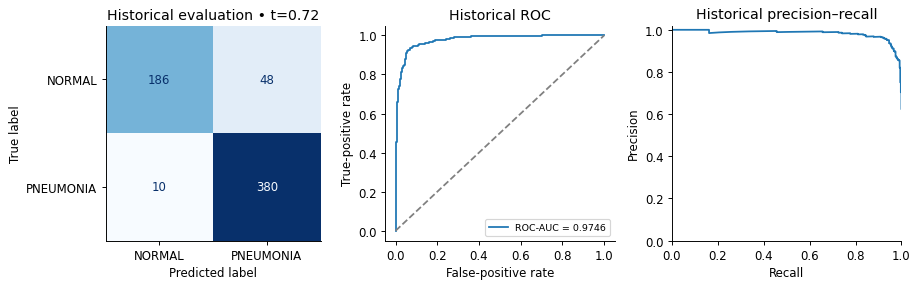

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
ConfusionMatrixDisplay(
    confusion_matrix(test_y, test_pred, labels=[0, 1]), display_labels=CLASS_NAMES
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Historical evaluation • t={THRESHOLD:.2f}")
fpr, tpr, _ = roc_curve(test_y, test_scores)
axes[1].plot(fpr, tpr, label=f'ROC-AUC = {test_result["roc_auc"]:.4f}')
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(
    xlabel="False-positive rate", ylabel="True-positive rate", title="Historical ROC"
)
axes[1].legend(fontsize=8)
precision, recall, _ = precision_recall_curve(test_y, test_scores)
axes[2].plot(recall, precision)
axes[2].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Historical precision–recall",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
fig.tight_layout()
fig.savefig(RUN_DIR / "historical_evaluation_curves.png", dpi=160, bbox_inches="tight")
plt.show()


### Supplemental evaluation by unique byte content

The primary result uses all supplied files. The supplemental calculation retains the first file, in deterministic file order, for each distinct SHA-256 value. It does not establish patient independence or detect visually similar/re-encoded images. Both results use the same frozen threshold; no threshold is selected from either historical report.


In [12]:
hash_label_counts = test_frame.groupby("sha256")["y_true"].nunique()
assert (hash_label_counts == 1).all()
unique_frame = test_frame.drop_duplicates("sha256", keep="first")
unique_result = binary_metrics(
    unique_frame["y_true"], unique_frame["p_pneumonia"], THRESHOLD
)
duplicate_frame = test_frame.loc[
    test_frame["sha256"].duplicated(keep=False)
].sort_values(["sha256", "file"])
duplicate_frame.to_csv(RUN_DIR / "historical_exact_duplicate_files.csv", index=False)
unique_frame.to_csv(RUN_DIR / "historical_unique_predictions.csv", index=False)
(RUN_DIR / "historical_unique_metrics.json").write_text(
    json.dumps(unique_result, indent=2)
)
display(
    pd.DataFrame(
        [
            dict(unit="All files", **test_result),
            dict(unit="Unique SHA-256 content", **unique_result),
        ]
    )
)
display(duplicate_frame[["file", "sha256", "y_true", "p_pneumonia"]])
print(
    f"{len(test_frame)} files; {len(unique_frame)} unique byte hashes; {len(test_frame)-len(unique_frame)} extra duplicate files; no conflicting labels."
)


,unit,threshold,n,tn,fp,fn,tp,accuracy,precision,recall,specificity,f1,roc_auc
0,All files,0.72,624,186,48,10,380,0.907051,0.887850,0.974359,0.794872,0.929095,0.974567
1,Unique SHA-256 content,0.72,618,185,46,10,377,0.909385,0.891253,0.974160,0.800866,0.930864,0.974608


,file,sha256,y_true,p_pneumonia
117,test/NORMAL/NORMAL2-IM-0173-0001-0001.jpeg,409f0f6c0f8a5b8ed4e0645633b07812aff5991aaee75b...,0,0.885366
118,test/NORMAL/NORMAL2-IM-0173-0001-0002.jpeg,409f0f6c0f8a5b8ed4e0645633b07812aff5991aaee75b...,0,0.885366
451,test/PNEUMONIA/person1661_virus_2872.jpeg,514afd0fa610117fbfef0e6e5b81a4d73a248158275941...,1,0.988170
452,test/PNEUMONIA/person1661_virus_2873.jpeg,514afd0fa610117fbfef0e6e5b81a4d73a248158275941...,1,0.988170
319,test/PNEUMONIA/person128_bacteria_606.jpeg,5824d55942d95216b7808fafa10db02aeaf63485a1a4f4...,1,0.996305
320,test/PNEUMONIA/person128_bacteria_607.jpeg,5824d55942d95216b7808fafa10db02aeaf63485a1a4f4...,1,0.996305
138,test/NORMAL/NORMAL2-IM-0246-0001-0001.jpeg,d33d41ad42d62152689b5e5939ee03a94fd827c707e47f...,0,0.785933
139,test/NORMAL/NORMAL2-IM-0246-0001-0002.jpeg,d33d41ad42d62152689b5e5939ee03a94fd827c707e47f...,0,0.785933
337,test/PNEUMONIA/person134_bacteria_643.jpeg,dfb4e7b7b96746cde5796d473f1667680020b2ca38cc7d...,1,0.943956
338,test/PNEUMONIA/person134_bacteria_644.jpeg,dfb4e7b7b96746cde5796d473f1667680020b2ca38cc7d...,1,0.943956


624 files; 618 unique byte hashes; 6 extra duplicate files; no conflicting labels.


## 9. Error analysis and example predictions

The complete error inventory includes the true class, predicted class, score and signed/absolute distance from the locked threshold. IM/NORMAL2 error rates use filename-prefix groups as descriptive categories; these are not verified acquisition sites. A confident mistake is not evidence that the clinical label is wrong. All scores are uncalibrated model outputs.

The prediction examples are the first TN, TP, FP and FN in deterministic file order. This rule avoids choosing examples because their appearance is persuasive, but four images are not representative of all errors.


In [13]:
test_frame["error_type"] = np.where(
    test_y == test_pred, "correct", np.where(test_y == 0, "FP", "FN")
)
test_frame["true_class"] = [CLASS_NAMES[int(y)] for y in test_y]
test_frame["predicted_class"] = [CLASS_NAMES[int(y)] for y in test_pred]
test_frame["filename_source"] = [filename_source(p) for p in historical_paths]
test_frame["signed_distance"] = test_scores - THRESHOLD
test_frame["absolute_distance"] = test_frame["signed_distance"].abs()
errors = test_frame.loc[test_frame["error_type"] != "correct"].sort_values(
    ["error_type", "absolute_distance"], ascending=[True, False]
)
error_columns = [
    "file",
    "true_class",
    "predicted_class",
    "error_type",
    "p_pneumonia",
    "signed_distance",
    "absolute_distance",
]
errors[error_columns + ["sha256"]].to_csv(
    RUN_DIR / "all_misclassifications.csv", index=False
)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(errors[error_columns])
normal_errors = (
    test_frame.loc[test_frame["y_true"] == 0]
    .groupby("filename_source")
    .agg(n=("file", "size"), false_positives=("y_pred", "sum"))
    .reset_index()
)
normal_errors["false_positive_rate"] = (
    normal_errors["false_positives"] / normal_errors["n"]
)
normal_errors.to_csv(RUN_DIR / "normal_filename_group_errors.csv", index=False)
display(normal_errors)
case_masks = {
    "TN": (test_y == 0) & (test_pred == 0),
    "TP": (test_y == 1) & (test_pred == 1),
    "FP": (test_y == 0) & (test_pred == 1),
    "FN": (test_y == 1) & (test_pred == 0),
}
example_indices = {
    name: int(np.flatnonzero(mask)[0])
    for name, mask in case_masks.items()
    if np.any(mask)
}


,file,true_class,predicted_class,error_type,p_pneumonia,signed_distance,absolute_distance
391,test/PNEUMONIA/person154_bacteria_728.jpeg,PNEUMONIA,NORMAL,FN,0.133509,-0.586491,0.586491
390,test/PNEUMONIA/person153_bacteria_726.jpeg,PNEUMONIA,NORMAL,FN,0.229989,-0.490011,0.490011
519,test/PNEUMONIA/person3_virus_17.jpeg,PNEUMONIA,NORMAL,FN,0.408637,-0.311363,0.311363
254,test/PNEUMONIA/person108_bacteria_511.jpeg,PNEUMONIA,NORMAL,FN,0.582218,-0.137782,0.137782
473,test/PNEUMONIA/person16_virus_47.jpeg,PNEUMONIA,NORMAL,FN,0.598764,-0.121236,0.121236
479,test/PNEUMONIA/person173_bacteria_831.jpeg,PNEUMONIA,NORMAL,FN,0.602048,-0.117952,0.117952
282,test/PNEUMONIA/person117_bacteria_557.jpeg,PNEUMONIA,NORMAL,FN,0.621164,-0.098836,0.098836
404,test/PNEUMONIA/person15_virus_46.jpeg,PNEUMONIA,NORMAL,FN,0.632702,-0.087298,0.087298
567,test/PNEUMONIA/person79_virus_148.jpeg,PNEUMONIA,NORMAL,FN,0.639713,-0.080287,0.080287
401,test/PNEUMONIA/person158_bacteria_745.jpeg,PNEUMONIA,NORMAL,FN,0.664504,-0.055496,0.055496


,filename_source,n,false_positives,false_positive_rate
0,IM,69,5,0.072464
1,NORMAL2,165,43,0.260606


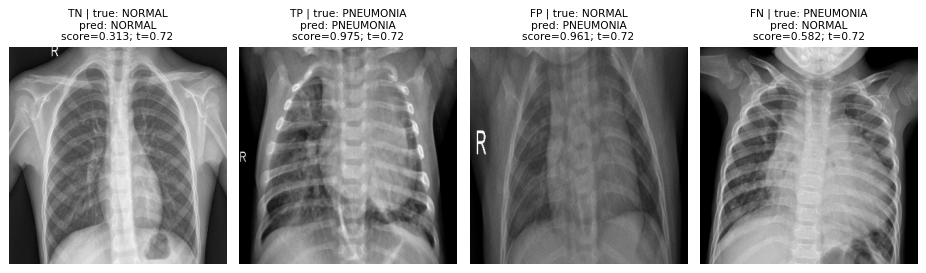

,category,file,true_class,predicted_class,pneumonia_score,threshold
0,TN,test/NORMAL/IM-0001-0001.jpeg,NORMAL,NORMAL,0.313236,0.72
1,TP,test/PNEUMONIA/person100_bacteria_475.jpeg,PNEUMONIA,PNEUMONIA,0.975341,0.72
2,FP,test/NORMAL/IM-0022-0001.jpeg,NORMAL,PNEUMONIA,0.960628,0.72
3,FN,test/PNEUMONIA/person108_bacteria_511.jpeg,PNEUMONIA,NORMAL,0.582218,0.72


In [14]:
def predict_image(path):
    """Return a research model prediction using the locked input pipeline."""
    image = decode_image(str(path))
    score = float(np.asarray(model(image[None, ...], training=False)).ravel()[0])
    return dict(
        predicted_class=CLASS_NAMES[int(score >= THRESHOLD)],
        pneumonia_score=score,
        threshold=THRESHOLD,
    )


fig, axes = plt.subplots(1, len(example_indices), figsize=(11, 3.5), squeeze=False)
example_rows = []
for ax, (category, i) in zip(axes.ravel(), example_indices.items()):
    result = predict_image(historical_paths[i])
    assert np.isclose(
        result["pneumonia_score"],
        test_scores[i],
        atol=CONFIG["prediction_atol"],
        rtol=CONFIG["prediction_rtol"],
    )
    image = decode_image(str(historical_paths[i])).numpy()
    ax.imshow(np.clip(image, 0, 255).astype(np.uint8))
    ax.axis("off")
    ax.set_title(
        f'{category} | true: {CLASS_NAMES[test_y[i]]}\npred: {result["predicted_class"]}\nscore={result["pneumonia_score"]:.3f}; t={THRESHOLD:.2f}',
        fontsize=9,
    )
    example_rows.append(
        dict(
            category=category,
            file=relative(historical_paths[i]),
            true_class=CLASS_NAMES[test_y[i]],
            **result,
        )
    )
fig.tight_layout()
fig.savefig(RUN_DIR / "example_predictions.png", dpi=160, bbox_inches="tight")
plt.show()
pd.DataFrame(example_rows).to_csv(RUN_DIR / "example_predictions.csv", index=False)
display(pd.DataFrame(example_rows))


## 10. Grad-CAM visualization

Grad-CAM averages gradients over the spatial dimensions of `last_conv_features`, weights the feature channels and retains positive contributions. For a positive prediction the target is the sigmoid pneumonia score; for a negative prediction it is **one minus that score**. The selected target class, score and decision threshold are shown for each example.

The heatmap is coarse and relative to its own maximum. A display cutoff of 0.25 changes only which heatmap pixels are overlaid; it does not change the classifier threshold. Activations near markers or the upper neck are a reason for further controlled analysis, not proof of a causal shortcut. There are no lesion annotations, localization accuracy measurements, model-randomization sanity tests or clinical validation of these maps. They cannot establish that the network used a medically correct feature.


The same deterministic TN/TP/FP/FN examples are retained, including attention outside the lung fields near an image marker or the neck. No example was removed, cropped or selected to conceal that behavior. Such attention is an observed interpretability concern; these maps alone cannot identify a causal shortcut or establish clinical correctness.

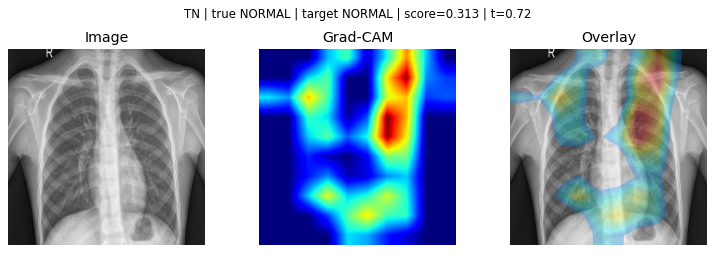

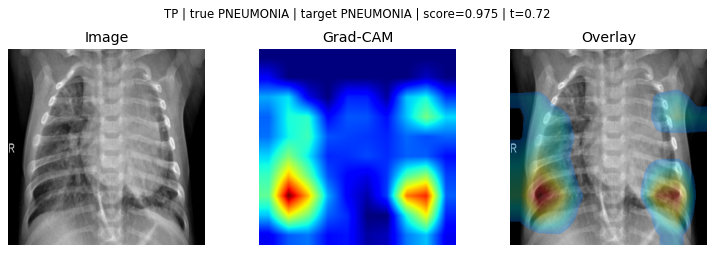

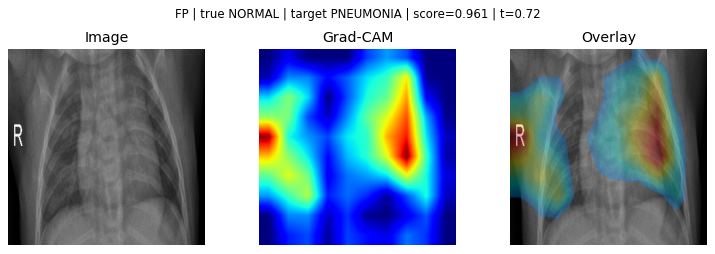

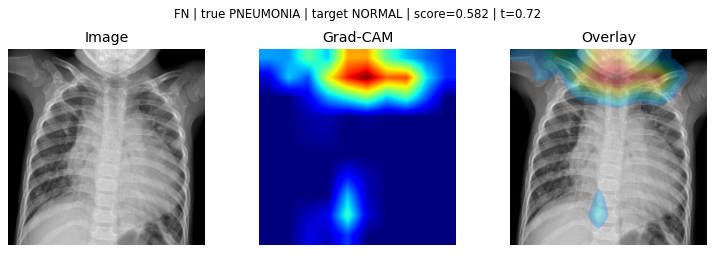

Four illustrative categories requested; available categories: ['TN', 'TP', 'FP', 'FN']


In [15]:
gradient_model = tf.keras.Model(
    model.inputs, [model.get_layer("last_conv_features").output, model.outputs[0]]
)


def gradcam(path, target_positive):
    """Explain the selected class score with positive gradient-weighted features."""
    image = decode_image(str(path))[None, ...]
    with tf.GradientTape() as tape:
        features, score = gradient_model(image, training=False)
        target = score[:, 0] if target_positive else 1.0 - score[:, 0]
    gradients = tape.gradient(target, features)
    if gradients is None:
        raise RuntimeError("Disconnected Grad-CAM gradient graph.")
    assert bool(tf.reduce_all(tf.math.is_finite(gradients)))
    weights = tf.reduce_mean(tf.cast(gradients, tf.float32), axis=(0, 1, 2))
    heat = tf.maximum(
        tf.reduce_sum(tf.cast(features[0], tf.float32) * weights, axis=-1), 0
    )
    heat = (heat / (tf.reduce_max(heat) + 1e-8)).numpy()
    return image.numpy()[0], cv2.resize(
        heat, (CONFIG["image_size"], CONFIG["image_size"])
    )


for category, i in example_indices.items():
    image, heat = gradcam(historical_paths[i], bool(test_pred[i]))
    original = np.clip(image, 0, 255).astype(np.uint8)
    colors = cv2.cvtColor(
        cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB
    )
    alpha = CONFIG["overlay_alpha"]
    overlay = np.where(
        (heat >= CONFIG["heatmap_display_cutoff"])[..., None],
        (1 - alpha) * original + alpha * colors,
        original,
    ).astype(np.uint8)
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    for ax, data, title in zip(
        axes, [original, heat, overlay], ["Image", "Grad-CAM", "Overlay"]
    ):
        ax.imshow(data, cmap="jet" if title == "Grad-CAM" else None)
        ax.axis("off")
        ax.set_title(title)
    fig.suptitle(
        f"{category} | true {CLASS_NAMES[test_y[i]]} | target {CLASS_NAMES[test_pred[i]]} | score={test_scores[i]:.3f} | t={THRESHOLD:.2f}",
        fontsize=10,
    )
    fig.tight_layout()
    fig.savefig(RUN_DIR / f"{category}_gradcam.png", dpi=160, bbox_inches="tight")
    plt.show()
print(
    "Four illustrative categories requested; available categories:",
    list(example_indices),
)


## 11. Limitations and appropriate follow-up

- **Adaptive benchmark reuse:** V1–V4 results informed later experiments. This notebook does not convert the historical benchmark into a new independent test or support a causal claim that one design change improved generalization.
- **Incomplete identity evidence:** filename groups and exact bytes are separated, but patient/site IDs and near-duplicate checks are unavailable. Subgroup performance, label reliability and representativeness remain unresolved.
- **Selection uncertainty:** one grouped validation fold and repeated checkpoint/threshold use can produce optimistic validation results. The 95% floors are empirical point-estimate selection constraints, not uncertainty bounds or clinical operating requirements.
- **Uncalibrated scores and limited explainability:** no probability calibration or external validation is established. Grad-CAM provides qualitative examples without lesion-localization ground truth or explanation sanity checks.
- **Training reproducibility:** seeds and code are available, but native original histories, optimizer state and epoch checkpoint files were not archived. Console records are rounded. Verification of the saved inference model does not reproduce the original training experiment.
- **Task and deployment scope:** the model uses resized RGB raster images and dataset folder labels. It is a research prototype with no demonstrated clinical utility or deployment safety.

A suitable next experiment would freeze the model checksum, preprocessing and threshold before accessing labels in an independent cohort. Define a compatible pneumonia label, verify age/acquisition suitability and trusted patient/site separation, audit duplicate/near-duplicate overlap, and predeclare endpoints and a patient/site-aware statistical plan. Do not tune on that cohort. No such independent evaluation has been performed here.


In [16]:
# Export current computations separately from immutable historical evidence.
packages = [
    "tensorflow",
    "keras",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "opencv-python-headless",
    "kagglehub",
    "nbformat",
    "nbclient",
    "ipykernel",
    "pillow",
]
versions = {name: importlib.metadata.version(name) for name in packages}
verification = dict(
    mode=(
        "explicit_fresh_training"
        if CONFIG["train_from_imagenet"]
        else "saved_model_reproduction"
    ),
    python=platform.python_version(),
    platform=platform.platform(),
    interpreter=Path(sys.executable).name,
    versions=versions,
    model_sha256=model_hash,
    validation_max_abs_difference=validation_max_error,
    historical_max_abs_difference=historical_max_error,
    reload_probe_max_abs_difference=reload_max_error,
    threshold=THRESHOLD,
    historical_metrics=test_result,
    unique_byte_metrics=unique_result,
    source_archive_sha256=source_hash_before,
    original_source_unchanged=hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()
    == source_hash_before,
    original_training_reproduced=False,
    independent_external_evaluation_performed=False,
)
assert verification["original_source_unchanged"]
assert len(errors) == test_result["fp"] + test_result["fn"]
(RUN_DIR / "verification.json").write_text(json.dumps(verification, indent=2))
(PROJECT_ROOT / "results/latest_run.json").write_text(
    json.dumps(
        dict(run_directory=RUN_DIR.relative_to(PROJECT_ROOT).as_posix()), indent=2
    )
)
print("Result files:", [p.name for p in sorted(RUN_DIR.iterdir())])
print(
    "Original notebook byte checksum unchanged:",
    verification["original_source_unchanged"],
)


Result files: ['all_misclassifications.csv', 'config.json', 'conflicting_hash_labels.csv', 'example_predictions.csv', 'example_predictions.png', 'FN_gradcam.png', 'FP_gradcam.png', 'fresh_vs_archived_metrics.csv', 'historical_evaluation_curves.png', 'historical_exact_duplicate_files.csv', 'historical_metrics.json', 'historical_predictions.csv', 'historical_unique_metrics.json', 'historical_unique_predictions.csv', 'image_inventory.csv', 'locked_run_policy.json', 'normal_filename_group_errors.csv', 'split_verification.json', 'TN_gradcam.png', 'TP_gradcam.png', 'training_curves.png', 'training_metric_history.csv', 'validation_predictions.csv', 'validation_threshold_grid.csv', 'validation_threshold_selection.png', 'verification.json']
Original notebook byte checksum unchanged: True


## 12. Conclusion

V5 demonstrates an end-to-end image-analysis workflow with explicit data-integrity checks, a portable Keras inference model, validation-based operating-point selection and reproducible evaluation code. The main performance report retains the original historical benchmark denominator, with a separate exact-byte-unique supplement and a complete error inventory.

The interpretation is deliberately limited: the benchmark informed development, patient/site independence is unverified, and the model and Grad-CAM maps have not been clinically validated. This code sample supports review of the implementation and experimental reasoning; an appropriate independent evaluation remains the next research step.


### References and evidence locations

- Dataset: [Kaggle Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia); [official KaggleHub client](https://github.com/Kaggle/kagglehub).
- APIs: [EfficientNetV2 input contract](https://keras.io/api/applications/efficientnet_v2/efficientnet_v2_models/), [transfer learning and fine-tuning](https://keras.io/guides/transfer_learning/), [Keras training/History](https://keras.io/guides/training_with_built_in_methods/), [BinaryAccuracy threshold](https://keras.io/api/metrics/accuracy_metrics/).
- Evaluation: [scikit-learn validation and test leakage guidance](https://scikit-learn.org/stable/modules/cross_validation.html); [original Grad-CAM paper](https://arxiv.org/abs/1610.02391).
- Project evidence: unchanged development record in `archive/`; original policies, manifests, predictions and rounded training-log provenance in `assets/`; current computations in `results/`; cell-by-cell findings and verification scope in `technical_audit_report.md` and `evidence/`.
